# 중고거래 사진 도우미 — 실행 노트북

모두의연구소 'AI가 이미지를 읽기까지' 05 실습 · 선택 과제 A.

순서: **이미지 경로 → 원본 · 박스 · 마스크 · 누끼 · JSON → conf 0.25 와 0.50 비교**.

- detection: `yolo26n.pt`, segmentation: `yolo26n-seg.pt` (COCO 80종, 추가 학습 없음)
- 설정: `imgsz=640`, `device=cpu`, `conf` 0.25 / 0.50
- 실행 위치: 로컬 Mac(CPU). 아래 첫 셀이 실제 버전과 실행 환경을 출력한다.
- 핵심 로직은 `market_helper.py` 에 있고, 이 노트북은 그것을 불러서 결과를 보여 준다.

## 0. 이미지 경로와 실행 환경
`IMAGE` 를 바꾸면 다른 사진으로 다시 돌릴 수 있다.

In [1]:
import json, platform, sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

import market_helper as mh

# 그림 제목의 한글이 네모로 깨지지 않게 (macOS 기본 한글 글꼴, 다른 OS면 영문 글꼴 그대로)
from matplotlib import font_manager
for f in ("AppleGothic", "Apple SD Gothic Neo", "NanumGothic", "Malgun Gothic"):
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

IMAGE = Path("input/laptop-desk.jpg")   # ← 여기만 바꾸면 된다 (input/bus.jpg, chair.jpg, backpack.jpg)
assert IMAGE.exists(), IMAGE

print("실행 위치:", platform.platform(), "/", platform.machine())
print("버전:", mh._versions())
print("설정:", {"imgsz": mh.IMGSZ, "device": mh.DEVICE, "det": mh.DET_WEIGHTS, "seg": mh.SEG_WEIGHTS})

실행 위치: macOS-27.2.1-arm64-arm-64bit / arm64


버전: {'python': '3.12.16', 'ultralytics': '8.4.208', 'torch': '2.15.0', 'opencv': '5.0.0', 'numpy': '2.5.4'}
설정: {'imgsz': 640, 'device': 'cpu', 'det': 'yolo26n.pt', 'seg': 'yolo26n-seg.pt'}


In [2]:
def show(paths_titles, cols=None, h=4):
    """(경로 또는 배열, 제목) 목록을 한 줄로 보여 준다. PNG 투명 영역은 체크무늬로 표시."""
    cols = cols or len(paths_titles)
    fig, axes = plt.subplots(1, cols, figsize=(h * 1.3 * cols, h), dpi=80)
    axes = np.atleast_1d(axes)
    for ax, (p, title) in zip(axes, paths_titles):
        im = cv2.imread(str(p), cv2.IMREAD_UNCHANGED) if not isinstance(p, np.ndarray) else p
        if im.ndim == 2:
            ax.imshow(im, cmap="gray")
        elif im.shape[2] == 4:
            rgb = cv2.cvtColor(im, cv2.COLOR_BGRA2RGBA)
            yy, xx = np.indices(rgb.shape[:2])
            checker = np.where(((yy // 20 + xx // 20) % 2)[..., None], 230, 255).astype(np.uint8)
            a = rgb[..., 3:4] / 255.0
            ax.imshow((rgb[..., :3] * a + checker * (1 - a)).astype(np.uint8))
        else:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. conf 0.25 로 분석
`analyze()` 는 detection 과 segmentation 을 둘 다 돌리고, 결과 이미지·마스크·누끼·`result.json` 을 `outputs/yolo/<사진>/conf_0.25/` 에 저장한다.

In [3]:
r = mh.analyze(IMAGE, conf=0.25)
out = Path(r["out_dir"])
print("저장 위치:", out.relative_to(mh.ROOT))
print("이미지 크기(w, h):", r["image_size_wh"])
for p in sorted(out.rglob("*")):
    if p.is_file() and not p.name.startswith("._"):
        print("  ", p.relative_to(out))

저장 위치: outputs/yolo/laptop-desk/conf_0.25
이미지 크기(w, h): [1280, 853]
   cutout.png
   cutout_white.jpg
   detect.jpg
   listing_thumb.jpg
   mask_overlay.jpg
   masks/00_laptop.png
   masks/01_potted_plant.png
   masks/02_tv.png
   masks/03_keyboard.png
   result.json
   segment.jpg


### 1-1. 원본 · detection 박스 · segmentation 마스크

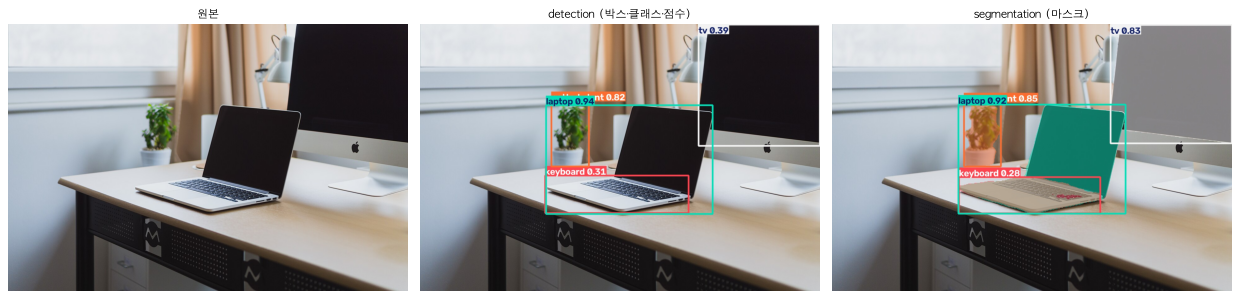

In [4]:
show([(IMAGE, "원본"), (out / "detect.jpg", "detection (박스·클래스·점수)"),
      (out / "segment.jpg", "segmentation (마스크)")])

### 1-2. 박스 JSON
좌표는 원본 픽셀 기준 `[x1, y1, x2, y2]`. 원본 이미지와 대조할 때 이 숫자를 쓴다.

In [5]:
print("detection")
for d in r["detections"]:
    print(f"  {d['class']:<13} score={d['score']:.3f}  box={d['box_xyxy']}  면적비={d['box_area_ratio']:.3f}")
print("segmentation")
for s in r["segments"]:
    print(f"  {s['class']:<13} score={s['score']:.3f}  box={s['box_xyxy']}  마스크 면적비={s['mask_area_ratio']:.3f}"
          f"  박스 중 마스크={s['mask_fill_of_box']:.2f}  가장자리={s['touches_edge']}  → {s['mask_file']}")

detection
  laptop        score=0.936  box=[403.8, 258.9, 936.7, 606.3]  면적비=0.170
  potted plant  score=0.822  box=[420.2, 245.3, 540.4, 454.3]  면적비=0.023
  tv            score=0.385  box=[891.8, 0.0, 1279.6, 388.1]  면적비=0.138
  keyboard      score=0.314  box=[400.3, 483.6, 859.7, 603.3]  면적비=0.050
segmentation
  laptop        score=0.915  box=[404.6, 257.0, 939.9, 605.1]  마스크 면적비=0.090  박스 중 마스크=0.53  가장자리=False  → masks/00_laptop.png
  potted plant  score=0.855  box=[422.2, 249.4, 540.1, 454.2]  마스크 면적비=0.016  박스 중 마스크=0.74  가장자리=False  → masks/01_potted_plant.png
  tv            score=0.833  box=[891.3, 1.5, 1279.7, 380.3]  마스크 면적비=0.120  박스 중 마스크=0.89  가장자리=True  → masks/02_tv.png
  keyboard      score=0.278  box=[406.2, 488.7, 858.8, 604.5]  마스크 면적비=0.028  박스 중 마스크=0.59  가장자리=False  → masks/03_keyboard.png


### 1-3. 저장된 마스크 파일 → 원본에 겹치기 → 누끼
화면에 그린 그림이 아니라 **디스크에 저장된 마스크 PNG** 를 다시 읽어서 겹친다. 그래서 그림과 파일이 같은 데이터임을 확인할 수 있다.

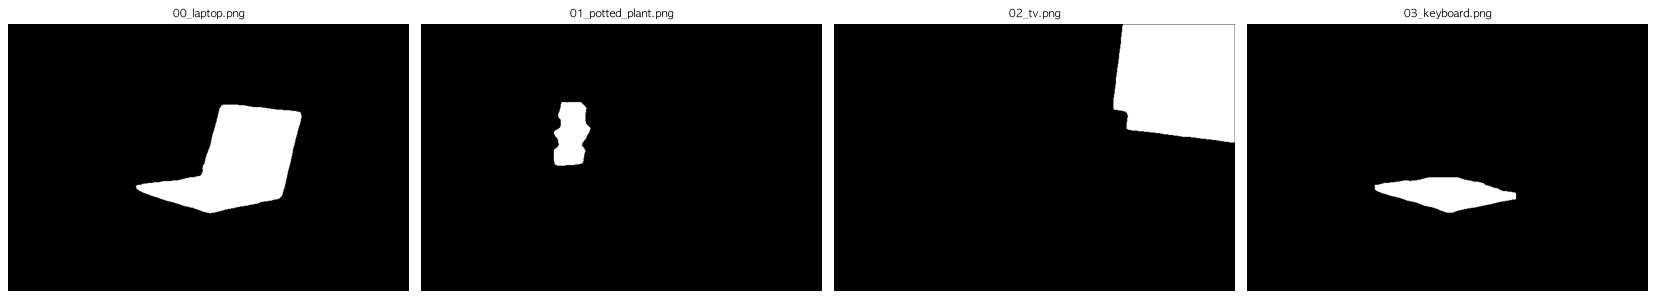

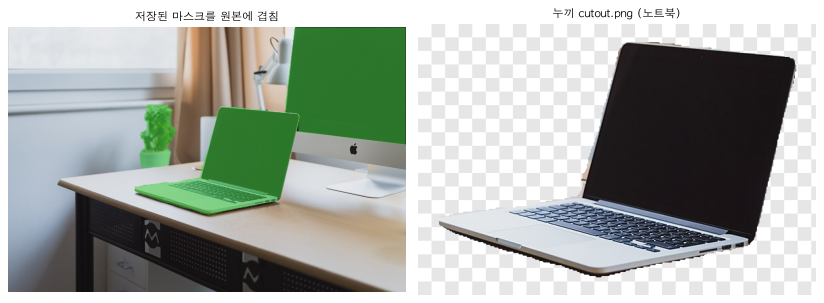

In [6]:
masks = sorted((out / "masks").glob("[!._]*.png"))
tiles = [(m, m.name) for m in masks[:4]]
if tiles:
    show(tiles)
listing = r["listing"]
cut = out / "cutout.png"
row = [(out / "mask_overlay.jpg", "저장된 마스크를 원본에 겹침")]
if listing["main_item"] and cut.exists():
    row.append((cut, f"누끼 cutout.png ({listing['main_item']['name_ko']})"))
show(row)

### 1-4. 판매용 정리 (`listing`)
대표 물건·카테고리·태그 후보·경고. 점수가 0.5 미만이거나 두 모델이 다르게 보면 `확인 필요`.

In [7]:
print(json.dumps({k: v for k, v in listing.items() if k not in ("draft", "checks")}, ensure_ascii=False, indent=2))

{
  "status": "자동 태그 가능",
  "review_reasons": [],
  "main_item": {
    "class": "laptop",
    "name_ko": "노트북",
    "category": "디지털기기",
    "score": 0.915,
    "source": "segmentation",
    "segment_id": 0,
    "detection_agrees": true,
    "touches_edge": false,
    "cutout_png": "cutout.png",
    "cutout_white_jpg": "cutout_white.jpg"
  },
  "listing_thumb": "listing_thumb.jpg",
  "listing_thumb_source": "segmentation 누끼",
  "privacy_safe": null,
  "parts_of_main": [
    "keyboard"
  ],
  "suggested_tags": [
    "가구/인테리어",
    "디지털기기"
  ],
  "warnings": [
    "노트북이(가) 사진의 9%만 차지합니다. 더 가까이에서 찍으면 목록 썸네일에서 잘 보입니다.",
    "다른 물건(TV/모니터, 화분)도 같이 찍혀 있습니다. 판매 물건이 무엇인지 헷갈릴 수 있어요."
  ],
  "models_disagree": false
}


### 1-5. 판매자에게 주는 결과: 목록 썸네일 · 사진 점검표 · 글 초안
썸네일은 누끼를 1080×1080 흰 정사각형 가운데에 놓은 것. 글 초안은 사진으로 알 수 없는 것(브랜드·상태·가격)을 지어내지 않고 빈칸으로 둔다.

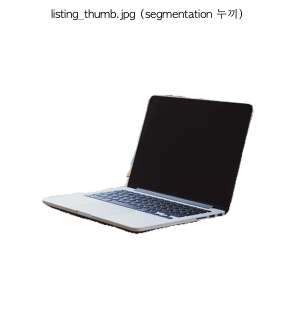

사진 점검표
  ⚠️ 물건이 충분히 크게 찍힘: 사진의 9% (기준 15%) → 더 가까이에서 찍으면 목록 썸네일에서 잘 보입니다.
  ✅ 물건 전체가 사진 안에 있음: 가장자리에 닿지 않음
  ⚠️ 판매 물건만 찍힘: 함께 찍힌 물건: TV/모니터, 화분 (대표 물건의 일부로 보고 제외: 키보드)
  ✅ 사람이 찍히지 않음: 사람 없음
  ✅ 동물이 찍히지 않음: 동물 없음
대표 물건의 일부로 보고 '다른 물건'에서 뺀 것: ['keyboard']

[글 초안]
제목: 노트북 팝니다 
카테고리: 디지털기기 
태그: ['노트북', '디지털기기']
노트북 판매합니다.

- 브랜드/모델명: (직접 입력)
- 구매 시기·사용 기간: (직접 입력)
- 상태: (흠집·고장·구성품 여부 직접 입력)
- 가격: (직접 입력)
- 거래 방법: (직거래 장소 / 택배)

※ 물건 이름과 카테고리는 사진 인식으로 추천한 값입니다. 올리기 전에 확인하세요.


In [8]:
row = []
if listing["listing_thumb"]:
    row.append((out / "listing_thumb.jpg", f"listing_thumb.jpg ({listing['listing_thumb_source']})"))
if listing["privacy_safe"]:
    row.append((out / "privacy_safe.jpg", "privacy_safe.jpg (사람 흐림)"))
if row:
    show(row)
mark = {True: "✅", False: "⚠️", None: "❓"}
print("사진 점검표")
for c in listing["checks"]:
    print(f"  {mark[c['ok']]} {c['item']}: {c['detail']}")
if listing["parts_of_main"]:
    print("대표 물건의 일부로 보고 '다른 물건'에서 뺀 것:", listing["parts_of_main"])
d = listing["draft"]
if d:
    print("\n[글 초안]\n제목:", d["title"], "\n카테고리:", d["category"], "\n태그:", d["tags"])
    print(d["body"])
    print("\n※", d["note"])

## 2. conf 0.25 와 0.50 비교
같은 사진을 두 임계값으로 **실제로 다시 돌린다**. 0.25 에서만 나온 대상 = 점수가 0.25~0.50 사이인 후보다.

In [9]:
rep = mh.compare(IMAGE)
for k, c in rep["count"].items():
    print(f"{k}: detection {c['detections']}개, segmentation {c['segments']}개")
print("0.25에서만 나온 detection :", [(d["class"], d["score"]) for d in rep["only_at_low_conf"]["detections"]] or "없음")
print("0.25에서만 나온 segment   :", [(d["class"], d["score"]) for d in rep["only_at_low_conf"]["segments"]] or "없음")
for k, m in rep["main_item"].items():
    st = rep["runs"][float(k.split("_")[1])]["listing"]["status"]
    print(f"{k} 대표 물건:", (m["name_ko"], m["category"], m["score"]) if m else None, "→", st)

conf_0.25: detection 4개, segmentation 4개
conf_0.50: detection 2개, segmentation 3개
0.25에서만 나온 detection : [('tv', 0.385), ('keyboard', 0.314)]
0.25에서만 나온 segment   : [('keyboard', 0.278)]
conf_0.25 대표 물건: ('노트북', '디지털기기', 0.915) → 자동 태그 가능
conf_0.50 대표 물건: ('노트북', '디지털기기', 0.915) → 자동 태그 가능


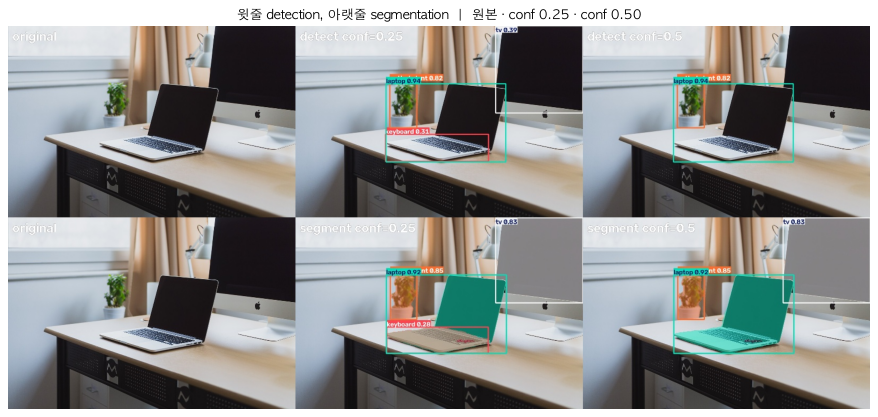

In [10]:
base = mh.OUT_ROOT / IMAGE.stem
img = cv2.imread(str(base / "side_by_side.jpg"))
plt.figure(figsize=(14, 14 * img.shape[0] / img.shape[1]), dpi=80)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("윗줄 detection, 아랫줄 segmentation  |  원본 · conf 0.25 · conf 0.50"); plt.show()

## 3. 네 장 전체 요약
`run.py` 와 같은 일을 한다(결과 저장 + `manifest.json` 갱신). 원본과 대조한 해석은 README 의 '원본 대조 검토 기록' 에 있다.

In [11]:
import json as _json
sources = _json.loads((mh.ROOT / "input/SOURCES.json").read_text(encoding="utf-8"))
inputs, outs = [], []
for p in sorted((mh.ROOT / "input").glob("[!._]*.jpg")):
    rp = mh.compare(p)
    l25 = rp["runs"][0.25]["listing"]; l50 = rp["runs"][0.5]["listing"]
    m = l25["main_item"]
    print(f"{p.name:<16} 0.25: {rp['count']['conf_0.25']}  0.50: {rp['count']['conf_0.50']}")
    print(f"{'':<16} 대표(0.25)={m['name_ko'] + '/' + m['category'] + ' ' + str(m['score']) if m else '없음'} "
          f"→ {l25['status']} | 0.50 → {l50['status']}")
    for w in l25["warnings"]:
        print(f"{'':<16} ⚠ {w}")
    inputs.append({"file": f"input/{p.name}", **sources.get(p.name, {})}); outs.append(f"outputs/yolo/{p.stem}/")
print("\nmanifest:", mh.write_manifest(inputs, outs).relative_to(mh.ROOT))

backpack.jpg     0.25: {'detections': 1, 'segments': 1}  0.50: {'detections': 0, 'segments': 0}
                 대표(0.25)=캐리어/가방/잡화 0.262 → 확인 필요 | 0.50 → 확인 필요


bus.jpg          0.25: {'detections': 5, 'segments': 5}  0.50: {'detections': 5, 'segments': 5}
                 대표(0.25)=없음 → 확인 필요 | 0.50 → 확인 필요
                 ⚠ 사람 4명이 찍혀 있습니다. privacy_safe.jpg 에 사람을 흐리게 처리했습니다(개인정보).


chair.jpg        0.25: {'detections': 1, 'segments': 1}  0.50: {'detections': 0, 'segments': 0}
                 대표(0.25)=의자/가구/인테리어 0.326 → 확인 필요 | 0.50 → 확인 필요


laptop-desk.jpg  0.25: {'detections': 4, 'segments': 4}  0.50: {'detections': 2, 'segments': 3}
                 대표(0.25)=노트북/디지털기기 0.915 → 자동 태그 가능 | 0.50 → 자동 태그 가능
                 ⚠ 노트북이(가) 사진의 9%만 차지합니다. 더 가까이에서 찍으면 목록 썸네일에서 잘 보입니다.
                 ⚠ 다른 물건(TV/모니터, 화분)도 같이 찍혀 있습니다. 판매 물건이 무엇인지 헷갈릴 수 있어요.

manifest: outputs/yolo/manifest.json
